# Image-ablation evaluation on the experimental test set

Evaluate the complete image-preprocessing ablation series on the established experimental test set: unmodified RGB, grayscale conversion, binary conversion, Gaussian smoothing (sigma 1, 2, 4, and 5), and bilateral filtering.

Every model is scored on the same 96 random-condition plus 36 fixed-condition patterns (132 total). The headline metric is per-image Hungarian point-matching F1 at a 4-pixel tolerance. The plot shows the mean plus or minus the standard deviation across test images.

In [11]:
import csv
import gc
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display
from matplotlib import font_manager as fm
from torch.utils.data import DataLoader

# Support launching here or from the repository root.
if not Path("expcolortoseed_dataset_ablation.py").is_file():
    notebook_dir = Path.cwd() / "information_encoding_decoding"
    if notebook_dir.is_dir():
        os.chdir(notebook_dir)

from expcolortoseed_dataset_ablation import MyDataset
from models.UNet_Resblocks import UNet_Resblocks
from utils import config
from utils.metrics import point_matching

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
print(f"Working directory: {Path.cwd()}")

Device: cuda
Working directory: /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/information_encoding_decoding


## Settings and corrected checkpoints

These are the corrected 3-left/2-right-crop, native-32x32-target runs. Grayscale and binary use their successful retry directories. The unmodified `none` run is the one-GPU RGB control from the same array, rather than the separate four-GPU baseline.

In [15]:
import sys as _path_sys
from pathlib import Path as _Path
_PAPER_ROOT = next(p for p in (_Path.cwd(), *_Path.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_PAPER_ROOT) not in _path_sys.path: _path_sys.path.insert(0, str(_PAPER_ROOT))
PREDICTION_THRESHOLD = 0.60
MATCHING_TOLERANCE = 4
BATCH_SIZE = 16
NUM_WORKERS = 4
OUTPUT_DIR = Path(__import__('paper_paths').inverse_results('image_ablation_evaluation_real_test_4gpu_lr5e4_original_v2'))

ABLATION_ROOT = Path(
    "lightning_logs/Res_UNet_exps_color_vae_nonrandom_vDiffusion_ablation"
)
COMMON_SUFFIX = (
    "_lambda0.5_pos2.0_features[16, 32, 64]_seeds_no_augmentation"
    "_crop3left2right_seed32_1gpu"
)

EXPERIMENTS = [
    # Original baseline: completed 4-GPU LR=5e-4 run; ablations retain 1 GPU / LR=1e-4.
    dict(condition="RGB control (4 GPUs, LR=5e-4)", short_label="RGB", ablation_type="none",
         gaussian_sigma=None, run_name="original_4gpu_lr5e4",
         checkpoint=Path(config.CKPT_PATH_SIMULATION_CONDITIONED_LR5E4_BEST)),
    dict(condition="Grayscale", short_label="Grayscale", ablation_type="grayscale",
         gaussian_sigma=None, run_name=f"grayscale{COMMON_SUFFIX}_retry59278902"),
    dict(condition="Binary mask", short_label="Binary", ablation_type="binary",
         gaussian_sigma=None, run_name=f"binary{COMMON_SUFFIX}_retry59278902"),
    dict(condition="Gaussian sigma 1", short_label="Gaussian sigma 1",
         ablation_type="gaussian", gaussian_sigma=1,
         run_name=f"gaussian_sigma1{COMMON_SUFFIX}"),
    dict(condition="Gaussian sigma 2", short_label="Gaussian sigma 2",
         ablation_type="gaussian", gaussian_sigma=2,
         run_name=f"gaussian_sigma2{COMMON_SUFFIX}"),
    dict(condition="Gaussian sigma 4", short_label="Gaussian sigma 4",
         ablation_type="gaussian", gaussian_sigma=4,
         run_name=f"gaussian_sigma4{COMMON_SUFFIX}"),
    dict(condition="Gaussian sigma 5", short_label="Gaussian sigma 5",
         ablation_type="gaussian", gaussian_sigma=5,
         run_name=f"gaussian_sigma5{COMMON_SUFFIX}"),
    dict(condition="Bilateral filter", short_label="Bilateral",
         ablation_type="bilateral", gaussian_sigma=None,
         run_name=f"bilateral{COMMON_SUFFIX}"),
]

def find_best_checkpoint(experiment):
    if 'checkpoint' in experiment:
        checkpoint = experiment['checkpoint']
        if not checkpoint.is_file():
            raise FileNotFoundError(checkpoint)
        return checkpoint
    checkpoint_dir = ABLATION_ROOT / experiment["run_name"] / "checkpoints"
    checkpoints = sorted(checkpoint_dir.glob("best-*.ckpt"))
    if len(checkpoints) != 1:
        raise FileNotFoundError(
            f"Expected one best checkpoint in {checkpoint_dir}, found {len(checkpoints)}"
        )
    return checkpoints[0]

selected = [(experiment, find_best_checkpoint(experiment)) for experiment in EXPERIMENTS]
display(pd.DataFrame([
    {"condition": experiment["condition"], "checkpoint": str(checkpoint)}
    for experiment, checkpoint in selected
]))

,condition,checkpoint
0,"RGB control (4 GPUs, LR=5e-4)",/hpc/dctrl/ks723/Physics_constrained_DL_patter...
1,Grayscale,lightning_logs/Res_UNet_exps_color_vae_nonrand...
2,Binary mask,lightning_logs/Res_UNet_exps_color_vae_nonrand...
3,Gaussian sigma 1,lightning_logs/Res_UNet_exps_color_vae_nonrand...
4,Gaussian sigma 2,lightning_logs/Res_UNet_exps_color_vae_nonrand...
5,Gaussian sigma 4,lightning_logs/Res_UNet_exps_color_vae_nonrand...
6,Gaussian sigma 5,lightning_logs/Res_UNet_exps_color_vae_nonrand...
7,Bilateral filter,lightning_logs/Res_UNet_exps_color_vae_nonrand...


## Audit the common test set

The source and target stems must match exactly within both test subsets. This audit is repeated for each preprocessing condition before inference.

In [16]:
def make_test_datasets(experiment):
    arguments = dict(
        use_vae=True,
        preprocess_input="backgroundwhite",
        ablation_type=experiment["ablation_type"],
        gaussian_sigma=experiment["gaussian_sigma"],
    )
    return [
        ("random", MyDataset(
            source_folder=config.EXP_FOLDER_TEST,
            target_folder=config.SEED_FOLDER_EXPTOSIM_TEST_32X32,
            **arguments,
        )),
        ("fixed", MyDataset(
            source_folder=config.EXP_FOLDER_EXPTOSIM_TEST_FIXED,
            target_folder=config.SEED_FOLDER_EXPTOSIM_TEST_FIXED_32X32,
            **arguments,
        )),
    ]

def audit_test_set(datasets):
    inventory = []
    seen = set()
    for subset, dataset in datasets:
        source_stems = [Path(path).stem for path in dataset.source_files]
        target_stems = [Path(path).stem for path in dataset.target_files]
        if source_stems != target_stems:
            raise ValueError(f"Source/target stem mismatch in the {subset} subset")
        keys = {(subset, stem) for stem in source_stems}
        if keys & seen:
            raise ValueError(f"Duplicate test keys in the {subset} subset")
        seen.update(keys)
        inventory.append({"subset": subset, "n_images": len(dataset)})
    return inventory

reference_inventory = audit_test_set(make_test_datasets(EXPERIMENTS[0]))
assert sum(row["n_images"] for row in reference_inventory) == 132, reference_inventory
for experiment in EXPERIMENTS[1:]:
    assert audit_test_set(make_test_datasets(experiment)) == reference_inventory
display(pd.DataFrame(reference_inventory))

,subset,n_images
0,random,96
1,fixed,36


## Freeze the selected checkpoints

Hard links make the evaluation reproducible without duplicating checkpoint storage. This cell refuses to overwrite an existing output directory; change `OUTPUT_DIR` above for a separate run.

In [17]:
from pathlib import Path as _DataPath
import sys as _data_sys
_DATA_ROOT = next(p for p in (_DataPath.cwd(), *_DataPath.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_DATA_ROOT) not in _data_sys.path: _data_sys.path.insert(0, str(_DATA_ROOT))
from paper_paths import figure_source_path as _figure_source_path
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
snapshot_dir = OUTPUT_DIR / "checkpoint_snapshot"
snapshot_dir.mkdir()
snapshots = []
for index, (experiment, source) in enumerate(selected):
    destination = snapshot_dir / f"{index:02d}_{experiment['run_name']}_{source.name}"
    os.link(source.resolve(), destination.resolve())
    snapshots.append((experiment, destination))

settings = {
    "device": str(device),
    "prediction_threshold": PREDICTION_THRESHOLD,
    "matching_algorithm": "hungarian",
    "matching_tolerance_pixels": MATCHING_TOLERANCE,
    "checkpoint_selection": "best validation loss (best-*.ckpt)",
    "test_set": reference_inventory,
    "number_test_images": sum(row["n_images"] for row in reference_inventory),
    "error_bars_in_plot": "standard deviation across per-image F1 scores",
    "experiments": [
        {
            "condition": experiment["condition"],
            "ablation_type": experiment["ablation_type"],
            "gaussian_sigma": experiment["gaussian_sigma"],
            "source_checkpoint": str(source.resolve()),
            "snapshot_checkpoint": str(snapshot.resolve()),
        }
        for (experiment, source), (_, snapshot) in zip(selected, snapshots)
    ],
}
with (_figure_source_path(OUTPUT_DIR / "evaluation_settings.json")).open("w") as handle:
    json.dump(settings, handle, indent=2)
print(f"Frozen {len(snapshots)} checkpoints in {snapshot_dir.resolve()}")

Frozen 8 checkpoints in /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/information_encoding_decoding/image_ablation_evaluation_real_test_4gpu_lr5e4_original_v2/checkpoint_snapshot


## Run inference and Hungarian matching

This is the long-running cell. It writes accumulated per-image and summary CSV files after each completed condition, so completed conditions survive an interrupted run.

In [18]:
from pathlib import Path as _DataPath
import sys as _data_sys
_DATA_ROOT = next(p for p in (_DataPath.cwd(), *_DataPath.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_DATA_ROOT) not in _data_sys.path: _data_sys.path.insert(0, str(_DATA_ROOT))
from paper_paths import figure_source_path as _figure_source_path
METRICS = ("tolerance_precision", "tolerance_recall", "tolerance_f1")

def evaluate_experiment(experiment, checkpoint):
    print(f"Evaluating {experiment['condition']}: {checkpoint}", flush=True)
    model = UNet_Resblocks.load_from_checkpoint(
        checkpoint, map_location=device
    ).eval().to(device)
    rows = []
    for subset, dataset in make_test_datasets(experiment):
        audit_test_set([(subset, dataset)])
        loader = DataLoader(
            dataset, batch_size=BATCH_SIZE, shuffle=False,
            num_workers=NUM_WORKERS, pin_memory=device.type == "cuda",
        )
        with torch.inference_mode():
            for batch in loader:
                source = batch["source"].to(device)
                prediction = torch.sigmoid(model(model.encode_source(source)))
                prediction = ((prediction > PREDICTION_THRESHOLD).to(torch.uint8) * 255).cpu()
                target = ((batch["target"] * 255).round().to(torch.uint8)).cpu()
                for index, stem in enumerate(batch["stem"]):
                    precision, recall, f1 = point_matching(
                        prediction[index, 0], target[index, 0],
                        tolerance_radius=MATCHING_TOLERANCE, algorithm="hungarian",
                    )
                    rows.append({
                        "condition": experiment["condition"],
                        "short_label": experiment["short_label"],
                        "ablation_type": experiment["ablation_type"],
                        "gaussian_sigma": experiment["gaussian_sigma"],
                        "subset": subset,
                        "stem": stem,
                        "tolerance_precision": precision,
                        "tolerance_recall": recall,
                        "tolerance_f1": f1,
                        "checkpoint": str(checkpoint.resolve()),
                    })
    del model
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return rows

def summarize(experiment, checkpoint, rows, subset):
    selected_rows = rows if subset == "all" else [
        row for row in rows if row["subset"] == subset
    ]
    result = {
        "condition": experiment["condition"],
        "short_label": experiment["short_label"],
        "ablation_type": experiment["ablation_type"],
        "gaussian_sigma": experiment["gaussian_sigma"],
        "subset": subset,
        "n_images": len(selected_rows),
        "checkpoint": str(checkpoint.resolve()),
        "checkpoint_selection": "best-*.ckpt",
    }
    for metric in METRICS:
        values = np.asarray([row[metric] for row in selected_rows], dtype=float)
        result[f"{metric}_mean"] = float(values.mean())
        result[f"{metric}_std"] = float(values.std())
        result[f"{metric}_sem"] = float(values.std(ddof=1) / np.sqrt(len(values)))
    return result

def write_csv(path, rows):
    with path.open("w", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=rows[0].keys())
        writer.writeheader()
        writer.writerows(rows)

all_rows, summaries = [], []
for experiment, checkpoint in snapshots:
    rows = evaluate_experiment(experiment, checkpoint)
    all_rows.extend(rows)
    summaries.extend(
        summarize(experiment, checkpoint, rows, subset)
        for subset in ("all", "random", "fixed")
    )
    write_csv(_figure_source_path(OUTPUT_DIR / "per_image_metrics.csv"), all_rows)
    write_csv(_figure_source_path(OUTPUT_DIR / "summary_metrics.csv"), summaries)
print(f"Completed {len(snapshots)} image-ablation conditions")

Evaluating RGB control (4 GPUs, LR=5e-4): image_ablation_evaluation_real_test_4gpu_lr5e4_original_v2/checkpoint_snapshot/00_original_4gpu_lr5e4_best-epoch=142-val_loss=0.3384.ckpt
Evaluating Grayscale: image_ablation_evaluation_real_test_4gpu_lr5e4_original_v2/checkpoint_snapshot/01_grayscale_lambda0.5_pos2.0_features[16, 32, 64]_seeds_no_augmentation_crop3left2right_seed32_1gpu_retry59278902_best-epoch=212-val_loss=0.3691.ckpt
Evaluating Binary mask: image_ablation_evaluation_real_test_4gpu_lr5e4_original_v2/checkpoint_snapshot/02_binary_lambda0.5_pos2.0_features[16, 32, 64]_seeds_no_augmentation_crop3left2right_seed32_1gpu_retry59278902_best-epoch=112-val_loss=0.4339.ckpt
Evaluating Gaussian sigma 1: image_ablation_evaluation_real_test_4gpu_lr5e4_original_v2/checkpoint_snapshot/03_gaussian_sigma1_lambda0.5_pos2.0_features[16, 32, 64]_seeds_no_augmentation_crop3left2right_seed32_1gpu_best-epoch=170-val_loss=0.3398.ckpt
Evaluating Gaussian sigma 2: image_ablation_evaluation_real_test_4

## Hungarian F1 results

The main table and plot use all 132 test images. PNG and vector PDF copies are saved in the evaluation output directory.

,condition,n_images,tolerance_precision_mean,tolerance_recall_mean,tolerance_f1_mean,tolerance_f1_std
0,"RGB control (4 GPUs, LR=5e-4)",132,0.780902,0.679196,0.681259,0.211254
1,Grayscale,132,0.758189,0.635357,0.652875,0.234586
2,Binary mask,132,0.668894,0.542094,0.558651,0.319287
3,Gaussian sigma 1,132,0.834686,0.682639,0.717510,0.234291
4,Gaussian sigma 2,132,0.802951,0.704253,0.724333,0.216227
5,Gaussian sigma 4,132,0.838319,0.668891,0.715157,0.220084
6,Gaussian sigma 5,132,0.774716,0.644137,0.672540,0.254511
7,Bilateral filter,132,0.786040,0.703983,0.711996,0.225225


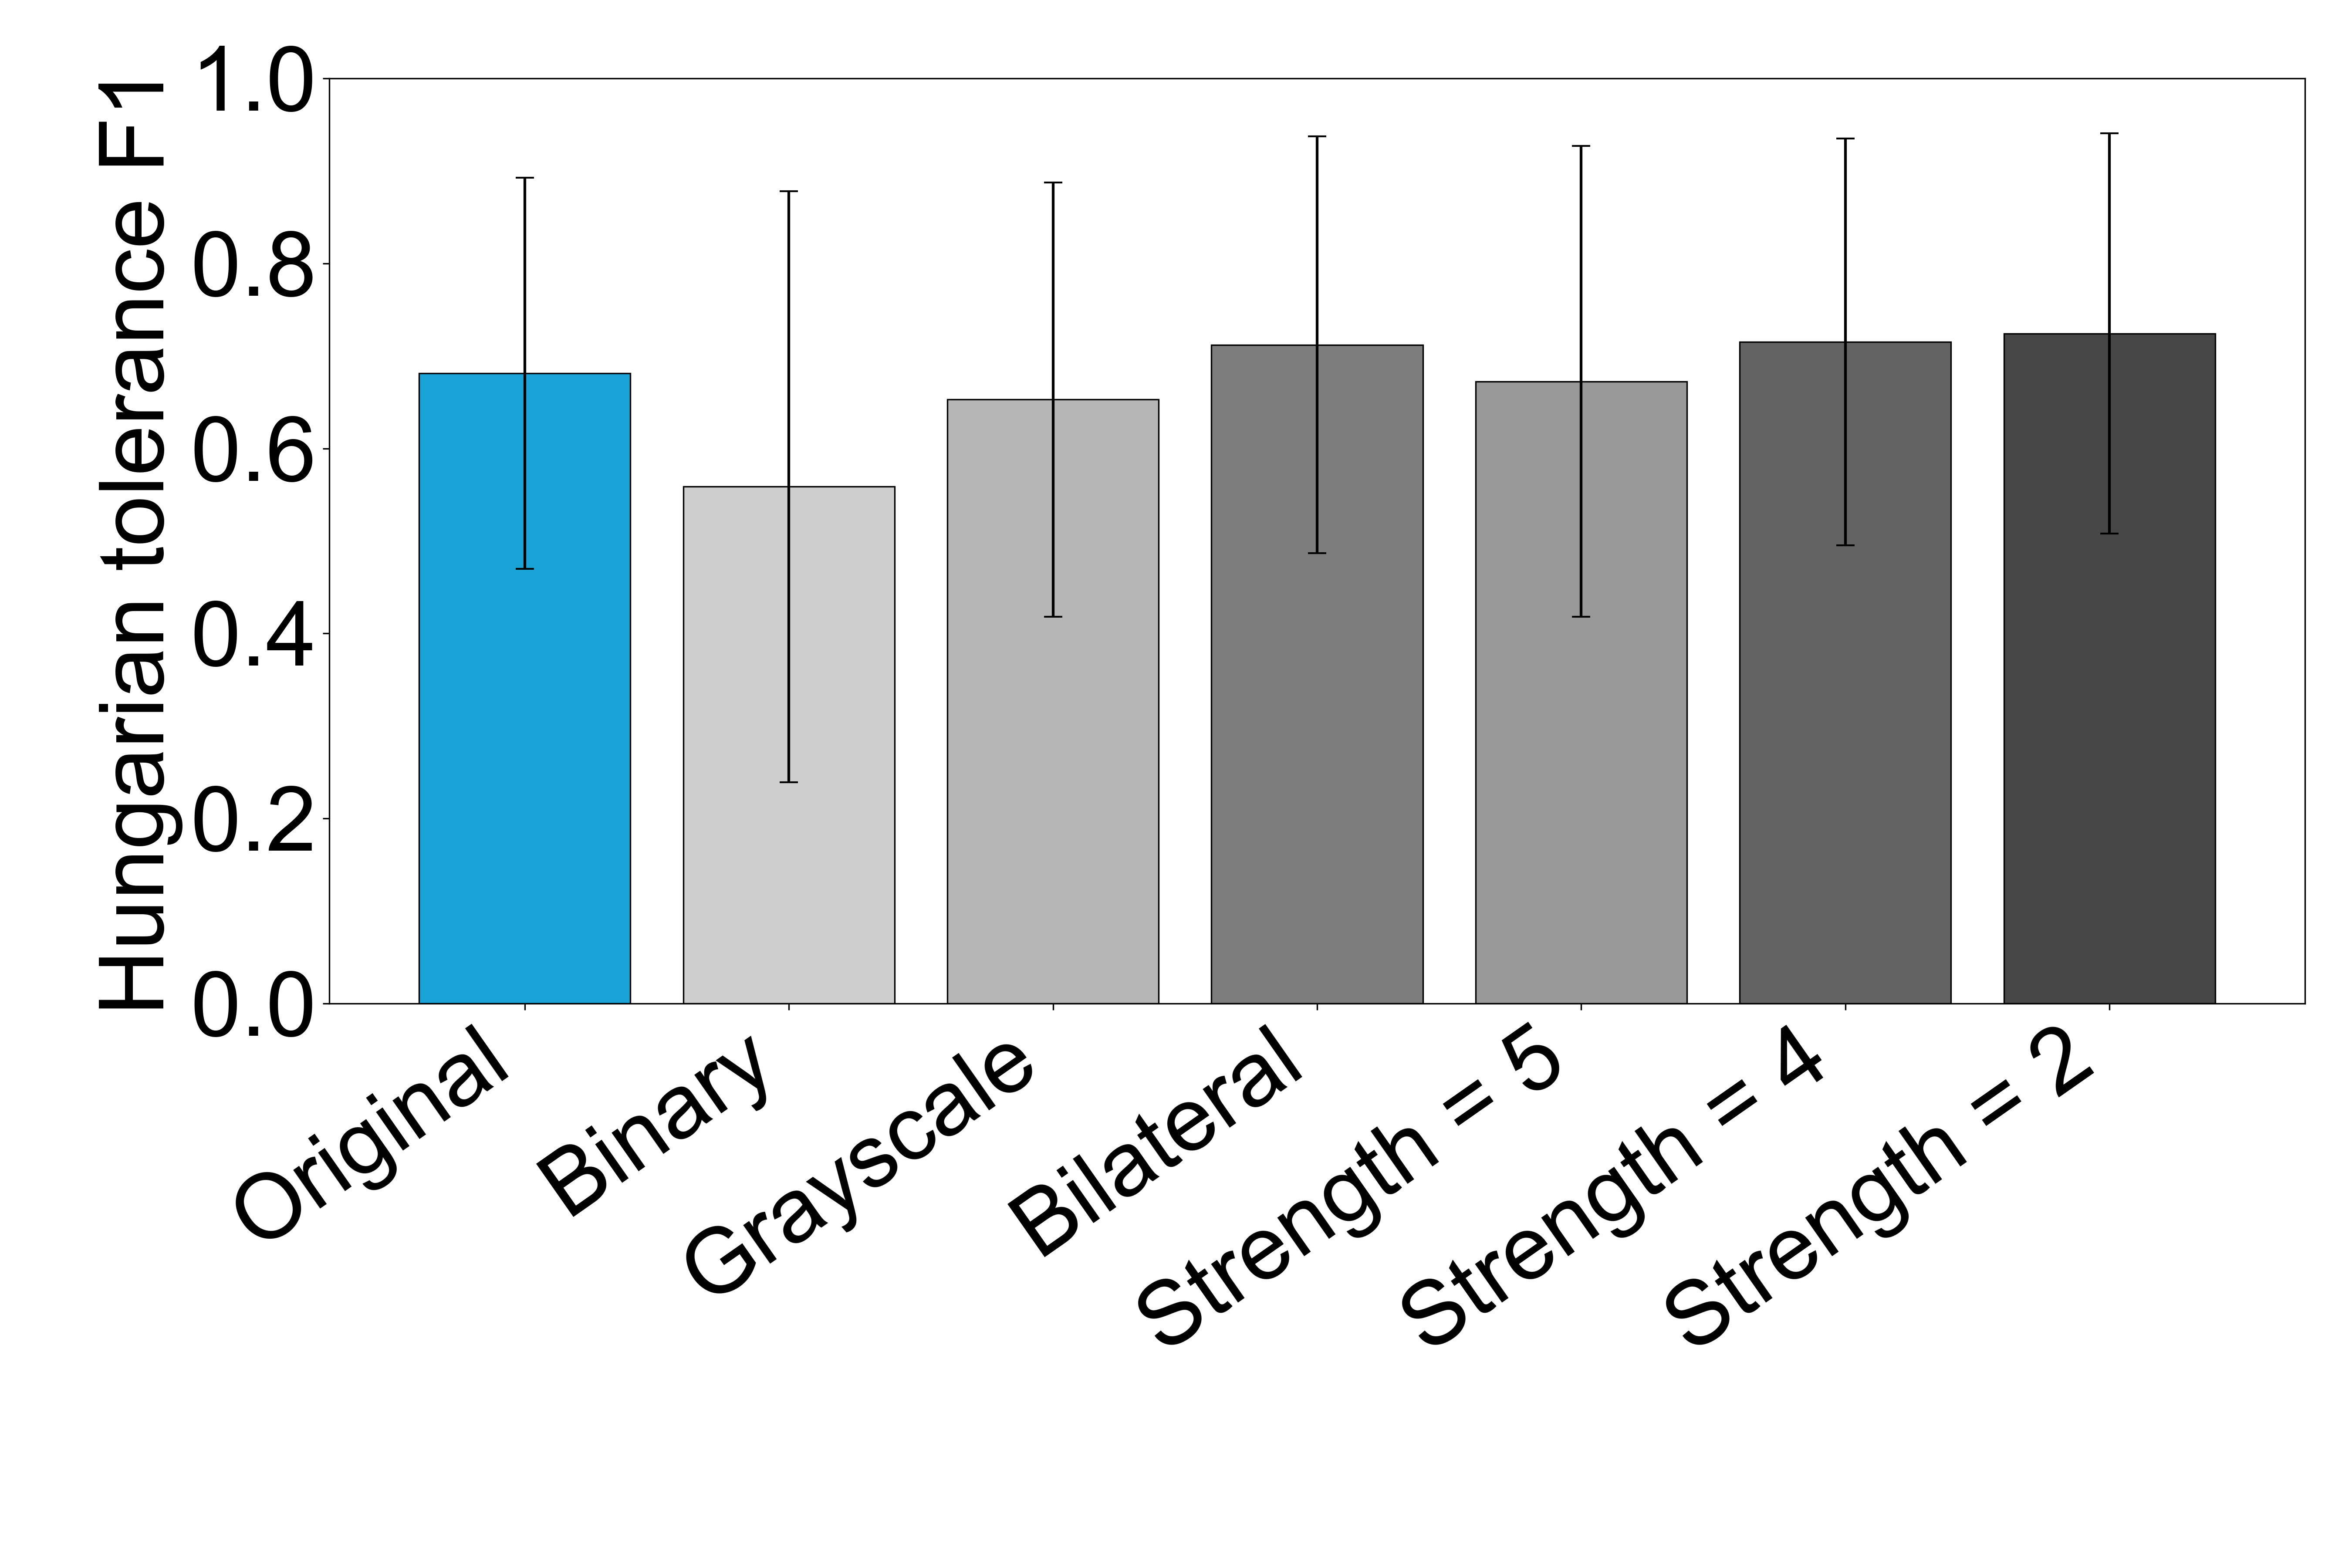

In [19]:
from pathlib import Path as _DataPath
import sys as _data_sys
_DATA_ROOT = next(p for p in (_DataPath.cwd(), *_DataPath.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_DATA_ROOT) not in _data_sys.path: _data_sys.path.insert(0, str(_DATA_ROOT))
from paper_paths import figure_source_path as _figure_source_path
summary = pd.read_csv(_figure_source_path(OUTPUT_DIR / "summary_metrics.csv"))
overall = summary.loc[summary["subset"] == "all"].copy()
display(overall[[
    "condition", "n_images", "tolerance_precision_mean",
    "tolerance_recall_mean", "tolerance_f1_mean",
    "tolerance_f1_std",
]].reset_index(drop=True))

if Path(config.FPATH).is_file():
    fm.fontManager.addfont(str(config.FPATH))
    plot_font = fm.FontProperties(fname=str(config.FPATH)).get_name()
else:
    plot_font = "sans-serif"

# Keep the RGB input as the reference; omit sigma 1 only from this plot.
plot_data = overall.loc[
    ~((overall["ablation_type"] == "gaussian") & (overall["gaussian_sigma"] == 1))
].copy()
original = plot_data.loc[plot_data["ablation_type"] == "none"]
non_gaussian = plot_data.loc[
    (plot_data["ablation_type"] != "none")
    & (plot_data["ablation_type"] != "gaussian")
].sort_values("tolerance_f1_mean")
gaussian = plot_data.loc[plot_data["ablation_type"] == "gaussian"].sort_values(
    "tolerance_f1_mean"
)
plot_data = pd.concat([original, non_gaussian, gaussian], ignore_index=True)

# Gray gets darker as mean F1 increases.
gray_rank = overall.loc[
    (overall["ablation_type"] != "none")
    & ~((overall["ablation_type"] == "gaussian") & (overall["gaussian_sigma"] == 1))
].sort_values("tolerance_f1_mean")
gray_values = np.linspace(0.30, 0.78, len(gray_rank))
gray_colors = {
    row["condition"]: plt.cm.Greys(value)
    for (_, row), value in zip(gray_rank.iterrows(), gray_values)
}
bar_colors = [
    "#1AA3D6" if row["ablation_type"] == "none" else gray_colors[row["condition"]]
    for _, row in plot_data.iterrows()
]
tick_labels = [
    "Original" if row["ablation_type"] == "none"
    else f"Strength = {int(row['gaussian_sigma'])}" if row["ablation_type"] == "gaussian"
    else row["short_label"]
    for _, row in plot_data.iterrows()
]

figure, axis = plt.subplots(figsize=(18, 12))
positions = np.arange(len(plot_data))
axis.bar(
    positions, plot_data["tolerance_f1_mean"],
    yerr=plot_data["tolerance_f1_std"], capsize=5,
    color=bar_colors, edgecolor="black", linewidth=0.8,
)
axis.set_xticks(positions, tick_labels, fontsize=50, rotation=35, ha="right")
axis.set_ylabel("Hungarian tolerance F1", fontsize=50, fontfamily=plot_font)
axis.set_ylim(0, 1)
axis.tick_params(axis="y", labelsize=50)
for label in (*axis.get_xticklabels(), *axis.get_yticklabels()):
    label.set_fontfamily(plot_font)

gaussian_start = len(original) + len(non_gaussian)
gaussian_end = gaussian_start + len(gaussian) - 1
figure.subplots_adjust(left=0.14, right=0.98, top=0.95, bottom=0.36)
figure.savefig(OUTPUT_DIR / "image_ablation_hungarian_f1.png", dpi=300)
figure.savefig(OUTPUT_DIR / "image_ablation_hungarian_f1.pdf")
plt.close(figure)
display(Image(filename=str(OUTPUT_DIR / "image_ablation_hungarian_f1.png")))


In [ ]:
from pathlib import Path as _ExportPath
import sys as _export_sys
_EXPORT_ROOT = next(p for p in (_ExportPath.cwd(), *_ExportPath.cwd().parents)
                    if (p / 'figure_exports').is_dir())
if str(_EXPORT_ROOT) not in _export_sys.path:
    _export_sys.path.insert(0, str(_EXPORT_ROOT))
import figure_exports as _figure_exports
# Vector PDF export: Supp. Fig. 24C — image perturbation ablation
# Run immediately after the preceding plotting/analysis cell.
from pathlib import Path
import runpy as _vector_runpy

# Locate the project from the notebook working directory; no sys.path changes.
VECTOR_PROJECT_ROOT = next(
    _p for _p in (Path.cwd(), *Path.cwd().parents)
    if (_p / 'figure_exports').is_dir()
)
save_vector_pdf = vars(_figure_exports)['save_vector_pdf']
VECTOR_DIR = VECTOR_PROJECT_ROOT / 'information_encoding_decoding' / 'vector based plots'

save_vector_pdf(figure, VECTOR_DIR / 'SuppFig24C_image_perturbations.pdf')


## Optional random/fixed subgroup results

In [ ]:
subgroup_columns = [
    "condition", "subset", "n_images",
    "tolerance_precision_mean", "tolerance_recall_mean",
    "tolerance_f1_mean", "tolerance_f1_sem",
]
display(summary.loc[summary["subset"] != "all", subgroup_columns].reset_index(drop=True))